# FlowRec filter statistics analysis

This notebook analyzes how different `min_user_interactions` and `min_item_interactions` values affect Amazon Review datasets **using the repository's own FlowRec data modules and preprocessors**.

Run it from the repository root, or make sure the repository root is on `PYTHONPATH`.

## 1. Parameters

Edit this cell for your dataset and filtering grid. The default settings match the `global_time` setup discussed in the experiments.

In [13]:
from types import SimpleNamespace
from pathlib import Path

# --- Dataset paths ---
reviews_path = "../data/raw/reviews_Musical_Instruments.json.gz"
metadata_path = "../data/raw/meta_Musical_Instruments.json.gz"   # set to None if not used
semantic_id_path = None                           # set path if semantic IDs should be loaded/filtered
item_key = "parent_asin"                          # "parent_asin" or "asin"

# --- Split configuration ---
split_strategy = "leave_one_out"                  # "global_time" or "leave_one_out"
global_val_ratio = 0.1
global_test_ratio = 0.1
global_val_timestamp = None
global_test_timestamp = None
global_history_policy = "rolling"                # "rolling" or "window_start"
global_eval_target_mode = "last_per_user"         # "all" or "last_per_user"

# --- Training-example construction ---
train_all_prefixes = False
train_target_policy = "last_n"                    # "all", "last", "last_n", "stride", "sampled", "hybrid"
train_last_n = 20
train_targets_per_user = 256
train_stride = 10
min_history_len = 1
max_history_len = 20

# --- Filter grid ---
min_user_values = [1, 3, 5, 10]
min_item_values = [1, 3, 5, 10]

# --- Additional preprocessing and post-filtering ---
deduplicate_consecutive = False
use_verified_only = False
filter_cold_items_after_split = True
cold_item_train_source = "observed"               # "observed" or "targets"

# --- Dataloader / reproducibility ---
batch_size = 256
eval_batch_size = 256
seed = 42

# --- Output ---
output_dir = Path("reports/beauty_filter_stats")
output_dir.mkdir(parents=True, exist_ok=True)

args = SimpleNamespace(
    reviews_path=reviews_path,
    metadata_path=metadata_path,
    semantic_id_path=semantic_id_path,
    item_key=item_key,
    split_strategy=split_strategy,
    global_val_ratio=global_val_ratio,
    global_test_ratio=global_test_ratio,
    global_val_timestamp=global_val_timestamp,
    global_test_timestamp=global_test_timestamp,
    global_history_policy=global_history_policy,
    global_eval_target_mode=global_eval_target_mode,
    train_all_prefixes=train_all_prefixes,
    train_target_policy=train_target_policy,
    train_last_n=train_last_n,
    train_targets_per_user=train_targets_per_user,
    train_stride=train_stride,
    min_history_len=min_history_len,
    max_history_len=max_history_len,
    deduplicate_consecutive=deduplicate_consecutive,
    use_verified_only=use_verified_only,
    filter_cold_items_after_split=filter_cold_items_after_split,
    cold_item_train_source=cold_item_train_source,
    batch_size=batch_size,
    eval_batch_size=eval_batch_size,
    seed=seed,
    output_dir=str(output_dir),
)


## 2. Imports

The notebook uses `flowrec.data` classes directly, so it should be executed inside the repository environment.

In [14]:
from __future__ import annotations

import gc
from collections import Counter, defaultdict
from dataclasses import asdict, replace
from pathlib import Path
from typing import Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image

from flowrec.data.datamodule import AmazonReviewDataConfig, AmazonReviewDataModule
from flowrec.data.datasets import SequenceExample
from flowrec.data.preprocessors import (
    apply_k_core_filter,
    count_interactions,
    deduplicate_consecutive_items,
    load_reviews_by_user,
    load_semantic_ids,
    sort_user_events,
)


## 3. Helper functions

These are adapted from the standalone script, but all CLI parsing has been removed.

In [15]:
def ensure_dir(path: str | Path) -> Path:
    out = Path(path)
    out.mkdir(parents=True, exist_ok=True)
    return out


def quantile_stats(values: Sequence[int] | np.ndarray, prefix: str) -> dict[str, float]:
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        return {
            f"{prefix}_count": 0,
            f"{prefix}_min": 0.0,
            f"{prefix}_mean": 0.0,
            f"{prefix}_std": 0.0,
            f"{prefix}_p25": 0.0,
            f"{prefix}_p50": 0.0,
            f"{prefix}_p75": 0.0,
            f"{prefix}_p90": 0.0,
            f"{prefix}_p95": 0.0,
            f"{prefix}_p99": 0.0,
            f"{prefix}_max": 0.0,
        }

    return {
        f"{prefix}_count": int(arr.size),
        f"{prefix}_min": float(np.min(arr)),
        f"{prefix}_mean": float(np.mean(arr)),
        f"{prefix}_std": float(np.std(arr)),
        f"{prefix}_p25": float(np.quantile(arr, 0.25)),
        f"{prefix}_p50": float(np.quantile(arr, 0.50)),
        f"{prefix}_p75": float(np.quantile(arr, 0.75)),
        f"{prefix}_p90": float(np.quantile(arr, 0.90)),
        f"{prefix}_p95": float(np.quantile(arr, 0.95)),
        f"{prefix}_p99": float(np.quantile(arr, 0.99)),
        f"{prefix}_max": float(np.max(arr)),
    }


def make_cfg(args, *, min_user: int, min_item: int) -> AmazonReviewDataConfig:
    return AmazonReviewDataConfig(
        reviews_path=args.reviews_path,
        metadata_path=args.metadata_path,
        semantic_id_path=args.semantic_id_path,
        item_key=args.item_key,
        split_strategy=args.split_strategy,
        global_val_ratio=args.global_val_ratio,
        global_test_ratio=args.global_test_ratio,
        global_val_timestamp=args.global_val_timestamp,
        global_test_timestamp=args.global_test_timestamp,
        global_history_policy=args.global_history_policy,
        global_eval_target_mode=args.global_eval_target_mode,
        train_all_prefixes=args.train_all_prefixes,
        train_target_policy=args.train_target_policy,
        train_last_n=args.train_last_n,
        train_targets_per_user=args.train_targets_per_user,
        train_stride=args.train_stride,
        min_history_len=args.min_history_len,
        min_user_interactions=min_user,
        min_item_interactions=min_item,
        max_history_len=args.max_history_len,
        deduplicate_consecutive=args.deduplicate_consecutive,
        use_verified_only=args.use_verified_only,
        batch_size=args.batch_size,
        eval_batch_size=args.eval_batch_size,
        num_workers=0,
        pin_memory=False,
        persistent_workers=False,
        include_raw_in_batch=False,
        filter_cold_items_after_split=args.filter_cold_items_after_split,
        cold_item_train_source=args.cold_item_train_source,
        seed=args.seed,
    )


def load_base_user_events(cfg: AmazonReviewDataConfig):
    """Load Amazon interactions using FlowRec repository preprocessors."""
    allowed_items = None
    if cfg.semantic_id_path is not None and cfg.drop_items_missing_semantic_id:
        semantic_ids, _ = load_semantic_ids(
            cfg.semantic_id_path,
            offset_by_one=cfg.offset_semantic_ids_by_one,
        )
        allowed_items = set(semantic_ids)

    user_events = load_reviews_by_user(
        cfg.reviews_path,
        item_key=cfg.item_key,
        use_verified_only=cfg.use_verified_only,
        keep_raw=cfg.keep_raw_reviews,
        allowed_items=allowed_items,
    )

    if cfg.deduplicate_consecutive:
        user_events = deduplicate_consecutive_items(user_events)

    return sort_user_events(user_events)


def raw_distribution_stats(base_user_events, *, min_user: int, min_item: int) -> tuple[dict, dict[str, np.ndarray]]:
    """Apply FlowRec k-core filtering and compute raw interaction distributions."""
    filtered = apply_k_core_filter(
        base_user_events,
        min_user_interactions=min_user,
        min_item_interactions=min_item,
    )
    filtered = sort_user_events(filtered)

    chain_lengths = np.asarray([len(events) for events in filtered.values()], dtype=int)
    item_counter = Counter(event.raw_item_id for events in filtered.values() for event in events)
    item_counts = np.asarray(list(item_counter.values()), dtype=int)
    num_interactions = int(count_interactions(filtered))
    num_users = int(len(filtered))
    num_items = int(len(item_counter))

    stats: dict[str, int | float] = {
        "raw_num_users_after_kcore": num_users,
        "raw_num_items_after_kcore": num_items,
        "raw_num_interactions_after_kcore": num_interactions,
        "raw_density_after_kcore": (
            num_interactions / (num_users * num_items)
            if num_users > 0 and num_items > 0
            else 0.0
        ),
    }
    stats.update(quantile_stats(chain_lengths, "raw_user_chain_len"))
    stats.update(quantile_stats(item_counts, "raw_item_interaction_count"))

    dists = {
        "raw_user_chain_len": chain_lengths,
        "raw_item_interaction_count": item_counts,
    }
    return stats, dists


def split_examples(dm: AmazonReviewDataModule, split: str) -> list[SequenceExample]:
    dataset = {
        "train": dm.train_dataset,
        "val": dm.val_dataset,
        "test": dm.test_dataset,
    }[split]
    if dataset is None:
        return []
    return list(dataset.examples)


def example_distribution_stats(examples: list[SequenceExample], prefix: str) -> tuple[dict, dict[str, np.ndarray]]:
    history_lengths = np.asarray([len(ex.history_item_ids) for ex in examples], dtype=int)
    target_positions = np.asarray([ex.target_position for ex in examples], dtype=int)
    users = {ex.user_id for ex in examples}
    target_items = [ex.target_item_id for ex in examples]
    target_item_counts = np.asarray(list(Counter(target_items).values()), dtype=int)

    observed_items_by_user: dict[int, set[int]] = defaultdict(set)
    for ex in examples:
        observed_items_by_user[ex.user_id].update(i for i in ex.history_item_ids if i > 0)
        if ex.target_item_id > 0:
            observed_items_by_user[ex.user_id].add(ex.target_item_id)
    visible_chain_lengths = np.asarray([len(v) for v in observed_items_by_user.values()], dtype=int)

    stats: dict[str, int | float] = {
        f"{prefix}_num_examples": int(len(examples)),
        f"{prefix}_num_users": int(len(users)),
        f"{prefix}_num_target_items": int(len(set(target_items))),
    }
    stats.update(quantile_stats(history_lengths, f"{prefix}_history_len"))
    stats.update(quantile_stats(target_positions, f"{prefix}_target_position"))
    stats.update(quantile_stats(target_item_counts, f"{prefix}_target_item_count"))
    stats.update(quantile_stats(visible_chain_lengths, f"{prefix}_visible_chain_len"))

    dists = {
        f"{prefix}_history_len": history_lengths,
        f"{prefix}_target_position": target_positions,
        f"{prefix}_target_item_count": target_item_counts,
        f"{prefix}_visible_chain_len": visible_chain_lengths,
    }
    return stats, dists


def datamodule_stats(cfg: AmazonReviewDataConfig) -> tuple[dict, dict[str, np.ndarray]]:
    """Run FlowRec's AmazonReviewDataModule and collect split-level statistics."""
    dm = AmazonReviewDataModule(cfg)
    dm.setup()

    summary = dm.summary()
    stats: dict[str, int | float | str | bool | None] = {}
    for key, value in summary.items():
        if key == "post_split_filter":
            continue
        if isinstance(value, (int, float, str, bool)) or value is None:
            stats[f"dm_{key}"] = value

    post = summary.get("post_split_filter")
    if isinstance(post, dict):
        for key, value in post.items():
            if isinstance(value, (int, float, str, bool)) or value is None:
                stats[f"post_filter_{key}"] = value

    all_dists: dict[str, np.ndarray] = {}
    for split in ("train", "val", "test"):
        split_stats, split_dists = example_distribution_stats(split_examples(dm, split), split)
        stats.update(split_stats)
        all_dists.update(split_dists)

    del dm
    gc.collect()
    return stats, all_dists


def metric_label(row: pd.Series) -> str:
    return f"u≥{int(row['min_user_interactions'])}, i≥{int(row['min_item_interactions'])}"


## 4. Plotting helpers

In [16]:
def plot_lines(summary: pd.DataFrame, metrics: list[str], *, title: str, ylabel: str, out_path: Path, log_y: bool = False) -> None:
    labels = summary["label"].tolist()
    x = np.arange(len(summary))
    fig, ax = plt.subplots(figsize=(max(10, 0.55 * len(labels)), 6))
    for metric in metrics:
        if metric in summary.columns:
            ax.plot(x, summary[metric].astype(float), marker="o", label=metric)
    ax.set_title(title)
    ax.set_xlabel("Filter setting")
    ax.set_ylabel(ylabel)
    if log_y:
        ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=220)
    plt.show()


def plot_quantiles(summary: pd.DataFrame, prefix: str, *, title: str, ylabel: str, out_path: Path, log_y: bool = False) -> None:
    metrics = [
        f"{prefix}_mean",
        f"{prefix}_p50",
        f"{prefix}_p75",
        f"{prefix}_p90",
        f"{prefix}_p95",
        f"{prefix}_p99",
    ]
    readable = {
        f"{prefix}_mean": "mean",
        f"{prefix}_p50": "p50",
        f"{prefix}_p75": "p75",
        f"{prefix}_p90": "p90",
        f"{prefix}_p95": "p95",
        f"{prefix}_p99": "p99",
    }
    labels = summary["label"].tolist()
    x = np.arange(len(summary))
    fig, ax = plt.subplots(figsize=(max(10, 0.55 * len(labels)), 6))
    for metric in metrics:
        if metric in summary.columns:
            ax.plot(x, summary[metric].astype(float), marker="o", label=readable[metric])
    ax.set_title(title)
    ax.set_xlabel("Filter setting")
    ax.set_ylabel(ylabel)
    if log_y:
        ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=220)
    plt.show()


def plot_stacked_examples(summary: pd.DataFrame, out_path: Path) -> None:
    labels = summary["label"].tolist()
    x = np.arange(len(summary))
    train = summary.get("train_num_examples", pd.Series([0] * len(summary))).astype(float)
    val = summary.get("val_num_examples", pd.Series([0] * len(summary))).astype(float)
    test = summary.get("test_num_examples", pd.Series([0] * len(summary))).astype(float)

    fig, ax = plt.subplots(figsize=(max(10, 0.55 * len(labels)), 6))
    ax.bar(x, train, label="train")
    ax.bar(x, val, bottom=train, label="val")
    ax.bar(x, test, bottom=train + val, label="test")
    ax.set_title("Constructed sequence examples after split and post-filtering")
    ax.set_xlabel("Filter setting")
    ax.set_ylabel("Number of examples")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=220)
    plt.show()


def plot_heatmap(summary: pd.DataFrame, metric: str, *, title: str, out_path: Path, log_values: bool = False) -> None:
    if metric not in summary.columns:
        return
    pivot = summary.pivot(
        index="min_user_interactions",
        columns="min_item_interactions",
        values=metric,
    ).sort_index().sort_index(axis=1)
    data = pivot.to_numpy(dtype=float)
    shown = np.log10(np.maximum(data, 1.0)) if log_values else data

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(shown, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("min_item_interactions")
    ax.set_ylabel("min_user_interactions")
    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels([str(c) for c in pivot.columns])
    ax.set_yticks(np.arange(len(pivot.index)))
    ax.set_yticklabels([str(i) for i in pivot.index])

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            value = data[i, j]
            if not np.isfinite(value):
                text = "nan"
            elif abs(value) >= 100000:
                text = f"{value:.1e}"
            elif abs(value) >= 100:
                text = f"{value:.0f}"
            else:
                text = f"{value:.2f}"
            ax.text(j, i, text, ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax, label="log10(value)" if log_values else metric)
    fig.tight_layout()
    fig.savefig(out_path, dpi=220)
    plt.show()


def save_plots(summary: pd.DataFrame, out_dir: Path) -> None:
    plots_dir = out_dir / "plots"
    plots_dir.mkdir(parents=True, exist_ok=True)

    plot_lines(
        summary,
        ["raw_num_users_after_kcore", "raw_num_items_after_kcore", "raw_num_interactions_after_kcore"],
        title="Raw dataset size after FlowRec k-core filtering",
        ylabel="Count",
        out_path=plots_dir / "raw_counts_after_kcore.png",
        log_y=True,
    )

    plot_lines(
        summary,
        ["dm_num_users", "dm_num_items", "dm_num_interactions"],
        title="DataModule catalog size after split and post-filtering",
        ylabel="Count",
        out_path=plots_dir / "datamodule_counts_after_split.png",
        log_y=True,
    )

    plot_stacked_examples(summary, plots_dir / "split_examples_stacked.png")

    plot_quantiles(
        summary,
        "raw_user_chain_len",
        title="Distribution of raw user chain lengths after filtering",
        ylabel="Interactions per user",
        out_path=plots_dir / "raw_user_chain_length_quantiles.png",
        log_y=True,
    )

    plot_quantiles(
        summary,
        "raw_item_interaction_count",
        title="Distribution of raw item interaction counts after filtering",
        ylabel="Interactions per item",
        out_path=plots_dir / "raw_item_interaction_count_quantiles.png",
        log_y=True,
    )

    for split in ("train", "val", "test"):
        plot_quantiles(
            summary,
            f"{split}_history_len",
            title=f"Distribution of {split} input history lengths",
            ylabel="History length in constructed examples",
            out_path=plots_dir / f"{split}_history_length_quantiles.png",
            log_y=False,
        )
        plot_quantiles(
            summary,
            f"{split}_target_item_count",
            title=f"Distribution of {split} target-item frequencies in examples",
            ylabel="Examples per target item",
            out_path=plots_dir / f"{split}_target_item_frequency_quantiles.png",
            log_y=True,
        )

    heatmaps = [
        ("raw_num_users_after_kcore", "Raw number of users after k-core", True),
        ("raw_num_items_after_kcore", "Raw number of items after k-core", True),
        ("raw_num_interactions_after_kcore", "Raw number of interactions after k-core", True),
        ("raw_user_chain_len_mean", "Mean raw user chain length", False),
        ("raw_user_chain_len_p95", "P95 raw user chain length", False),
        ("raw_item_interaction_count_mean", "Mean raw item interaction count", False),
        ("raw_item_interaction_count_p95", "P95 raw item interaction count", False),
        ("train_num_examples", "Number of train examples", True),
        ("val_num_examples", "Number of validation examples", True),
        ("test_num_examples", "Number of test examples", True),
        ("post_filter_num_items_removed", "Items removed by post-split cold filtering", True),
        ("post_filter_dropped_val_examples", "Validation examples dropped by cold filtering", True),
        ("post_filter_dropped_test_examples", "Test examples dropped by cold filtering", True),
    ]
    for metric, title, log_values in heatmaps:
        plot_heatmap(
            summary,
            metric,
            title=title,
            out_path=plots_dir / f"heatmap_{metric}.png",
            log_values=log_values,
        )


## 5. Run analysis

This cell loads base events once, then evaluates each pair of filter values.

In [17]:
out_dir = ensure_dir(args.output_dir)

base_cfg = make_cfg(args, min_user=1, min_item=0)
print("Loading base interactions with FlowRec preprocessors...")
base_user_events = load_base_user_events(base_cfg)
print(f"Loaded {len(base_user_events):,} users before k-core grid evaluation.")

rows: list[dict] = []

for min_user in min_user_values:
    for min_item in min_item_values:
        print(f"\n=== min_user_interactions={min_user}, min_item_interactions={min_item} ===")
        cfg = make_cfg(args, min_user=min_user, min_item=min_item)

        raw_stats, _ = raw_distribution_stats(
            base_user_events,
            min_user=min_user,
            min_item=min_item,
        )
        dm_stats, _ = datamodule_stats(cfg)

        row = {
            "min_user_interactions": min_user,
            "min_item_interactions": min_item,
            **raw_stats,
            **dm_stats,
        }
        rows.append(row)
        print(
            "raw users/items/interactions="
            f"{raw_stats['raw_num_users_after_kcore']:,}/"
            f"{raw_stats['raw_num_items_after_kcore']:,}/"
            f"{raw_stats['raw_num_interactions_after_kcore']:,}; "
            "examples train/val/test="
            f"{dm_stats.get('train_num_examples', 0):,}/"
            f"{dm_stats.get('val_num_examples', 0):,}/"
            f"{dm_stats.get('test_num_examples', 0):,}"
        )

summary = pd.DataFrame(rows)
summary["label"] = summary.apply(metric_label, axis=1)
summary = summary.sort_values(["min_user_interactions", "min_item_interactions"]).reset_index(drop=True)

summary_path = out_dir / "flowrec_filter_statistics.csv"
summary.to_csv(summary_path, index=False)
summary.to_json(out_dir / "flowrec_filter_statistics.json", orient="records", indent=2)

print(f"\nSaved summary: {summary_path}")
print(f"Saved JSON:    {out_dir / 'flowrec_filter_statistics.json'}")

display(summary.head())


Loading base interactions with FlowRec preprocessors...
Loaded 339,231 users before k-core grid evaluation.

=== min_user_interactions=1, min_item_interactions=1 ===
raw users/items/interactions=339,231/83,046/500,176; examples train/val/test=57,231/19,517/19,359

=== min_user_interactions=1, min_item_interactions=3 ===
raw users/items/interactions=307,585/31,269/433,191; examples train/val/test=41,706/18,485/18,658

=== min_user_interactions=1, min_item_interactions=5 ===
raw users/items/interactions=283,023/18,363/389,631; examples train/val/test=33,662/17,201/17,185

=== min_user_interactions=1, min_item_interactions=10 ===
raw users/items/interactions=246,742/8,935/328,888; examples train/val/test=23,664/14,403/14,333

=== min_user_interactions=3, min_item_interactions=1 ===
raw users/items/interactions=29,040/48,792/150,708; examples train/val/test=57,231/19,517/19,359

=== min_user_interactions=3, min_item_interactions=3 ===
raw users/items/interactions=17,500/9,237/82,855; examp

,min_user_interactions,min_item_interactions,raw_num_users_after_kcore,raw_num_items_after_kcore,raw_num_interactions_after_kcore,raw_density_after_kcore,raw_user_chain_len_count,raw_user_chain_len_min,raw_user_chain_len_mean,raw_user_chain_len_std,...,test_visible_chain_len_mean,test_visible_chain_len_std,test_visible_chain_len_p25,test_visible_chain_len_p50,test_visible_chain_len_p75,test_visible_chain_len_p90,test_visible_chain_len_p95,test_visible_chain_len_p99,test_visible_chain_len_max,label
0,1,1,339231,83046,500176,0.000018,339231,1.0,1.474441,2.342604,...,4.609742,3.177015,3.0,4.0,5.0,8.0,11.0,20.0,21.0,"u≥1, i≥1"
1,1,3,307585,31269,433191,0.000045,307585,1.0,1.408362,1.659211,...,4.547111,3.026477,3.0,4.0,5.0,8.0,10.0,20.0,21.0,"u≥1, i≥3"
2,1,5,283023,18363,389631,0.000075,283023,1.0,1.376676,1.418386,...,4.508176,2.894268,3.0,4.0,5.0,7.0,10.0,19.0,21.0,"u≥1, i≥5"
3,1,10,246742,8935,328888,0.000149,246742,1.0,1.332923,1.205864,...,4.397544,2.651465,3.0,3.0,5.0,7.0,9.0,17.0,21.0,"u≥1, i≥10"
4,3,1,29040,48792,150708,0.000106,29040,3.0,5.189669,6.915874,...,4.609742,3.177015,3.0,4.0,5.0,8.0,11.0,20.0,21.0,"u≥3, i≥1"


## 6. Generate and save plots

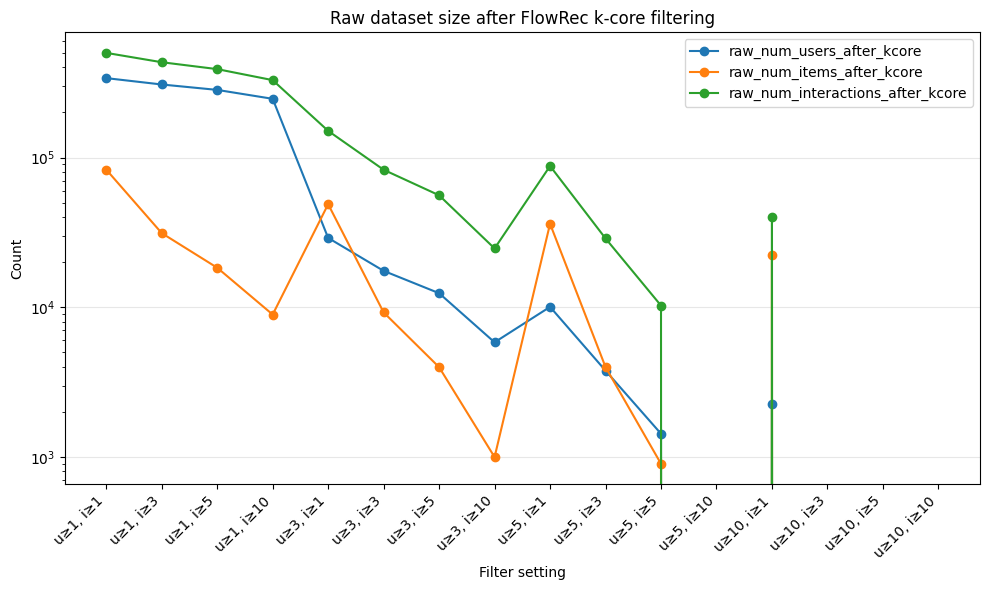

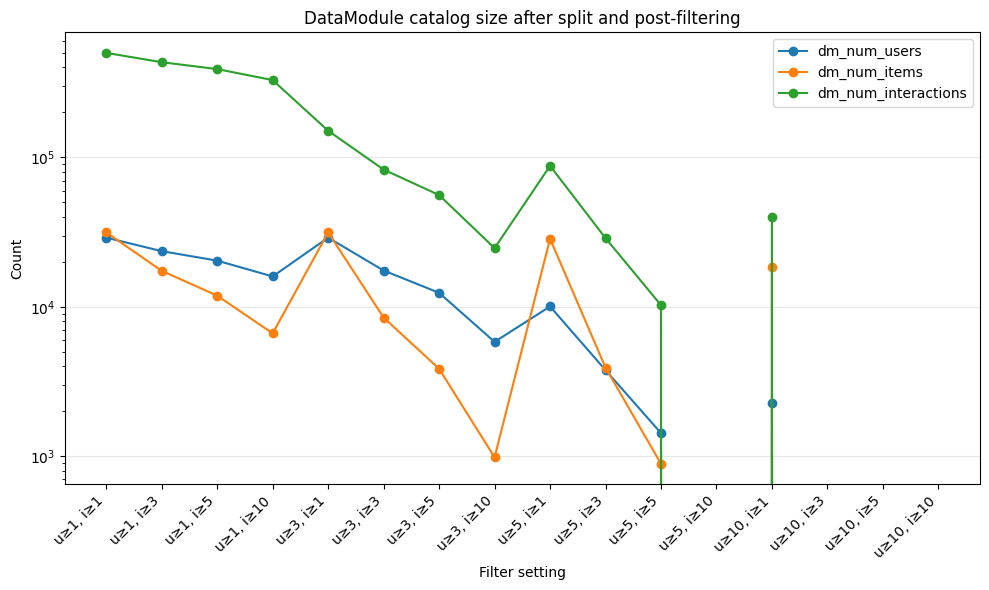

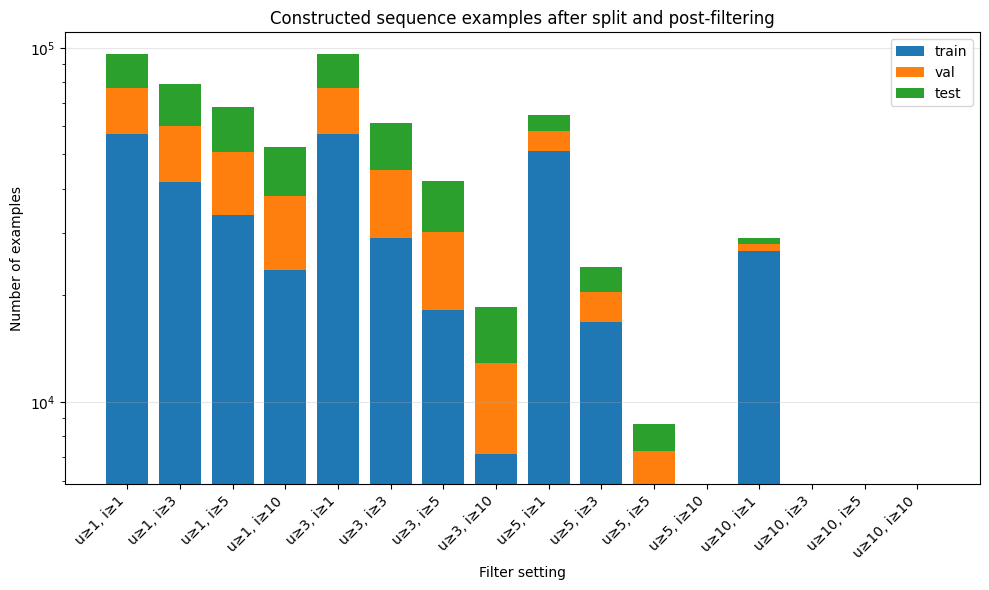

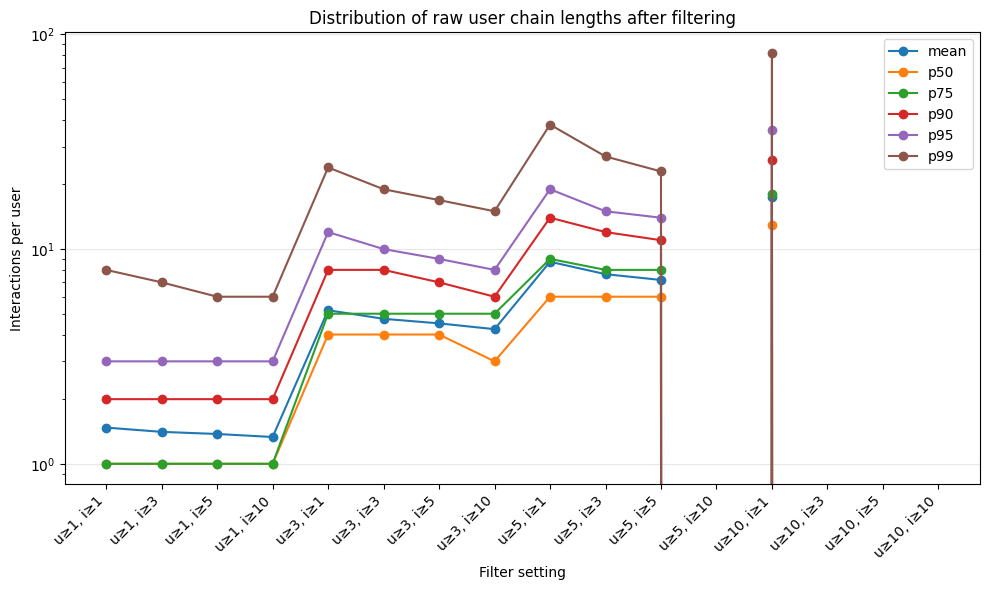

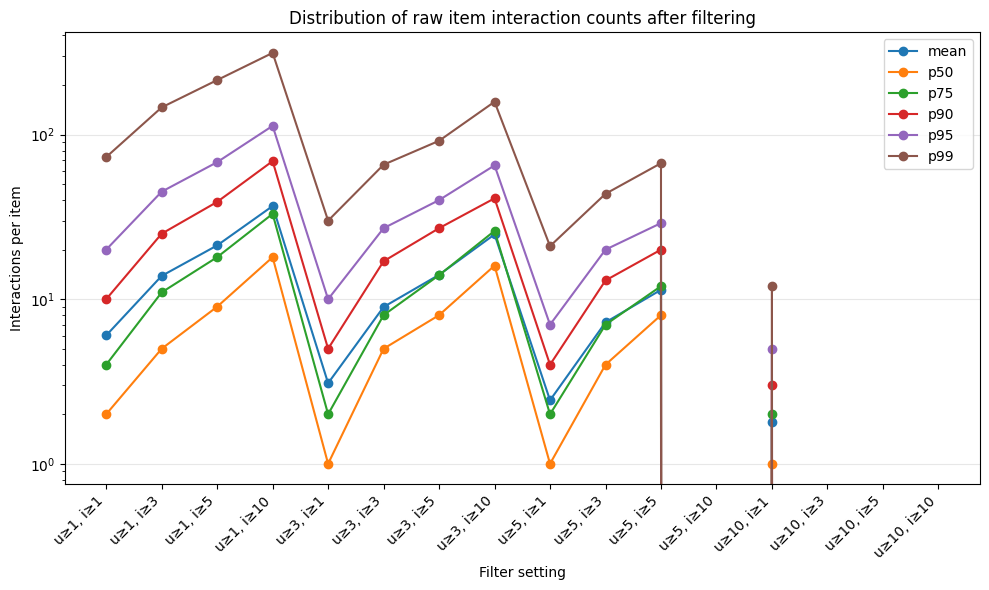

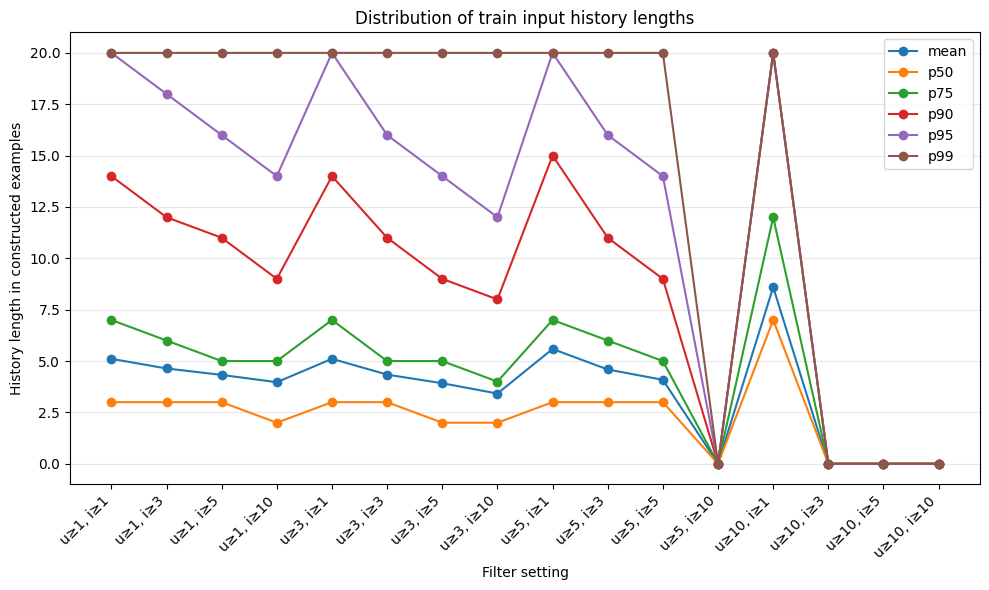

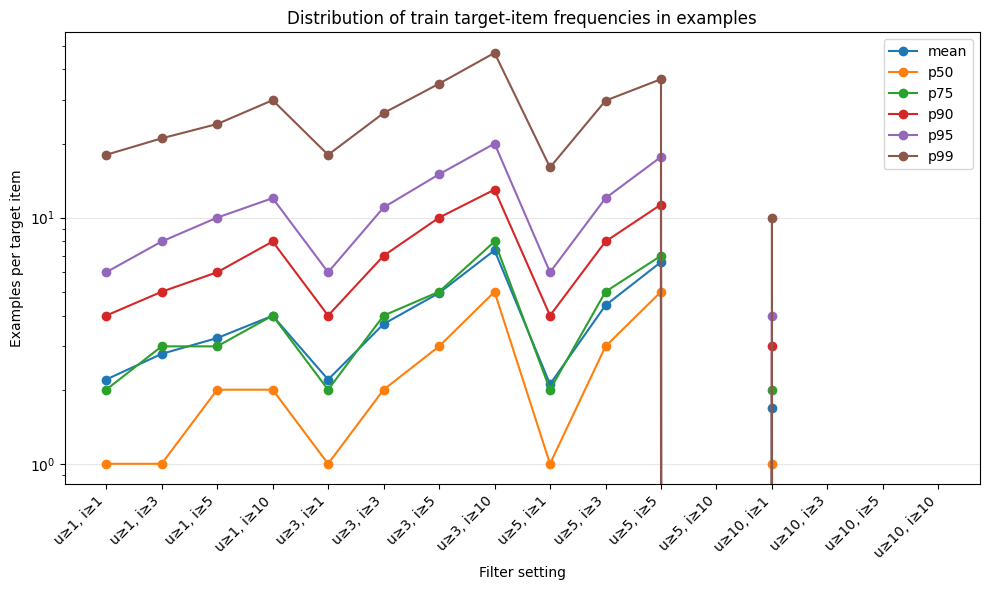

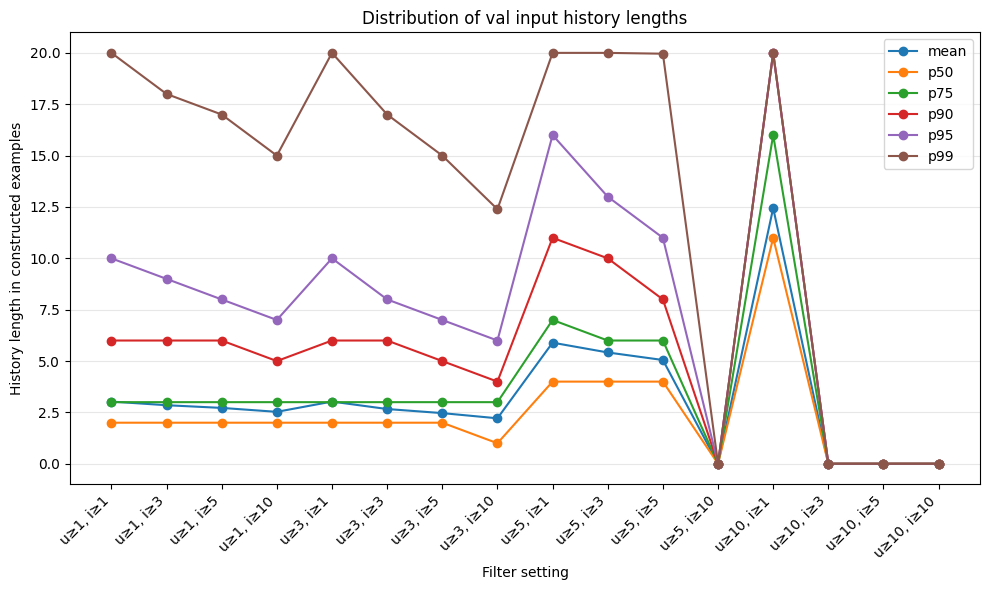

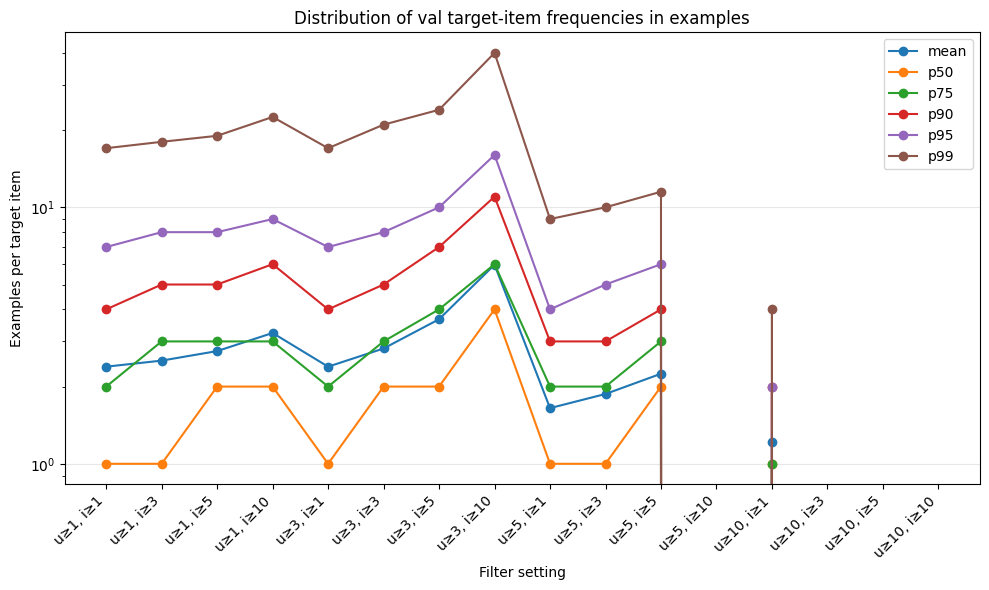

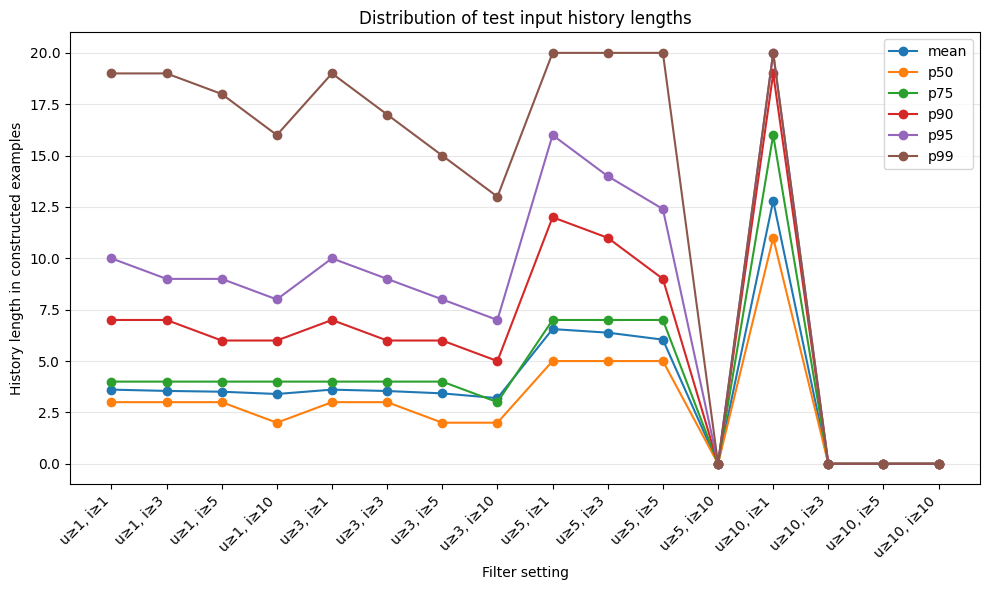

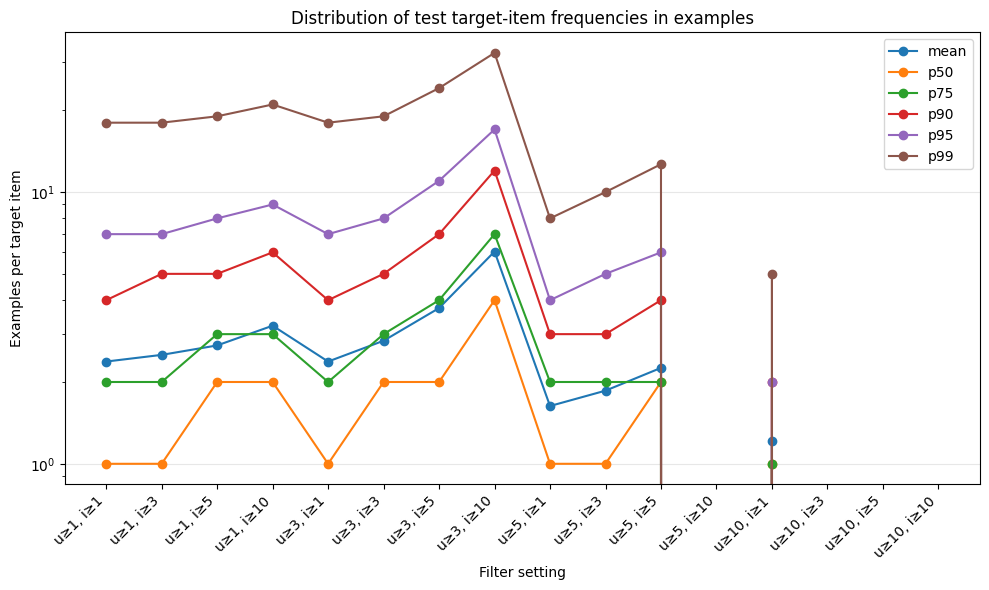

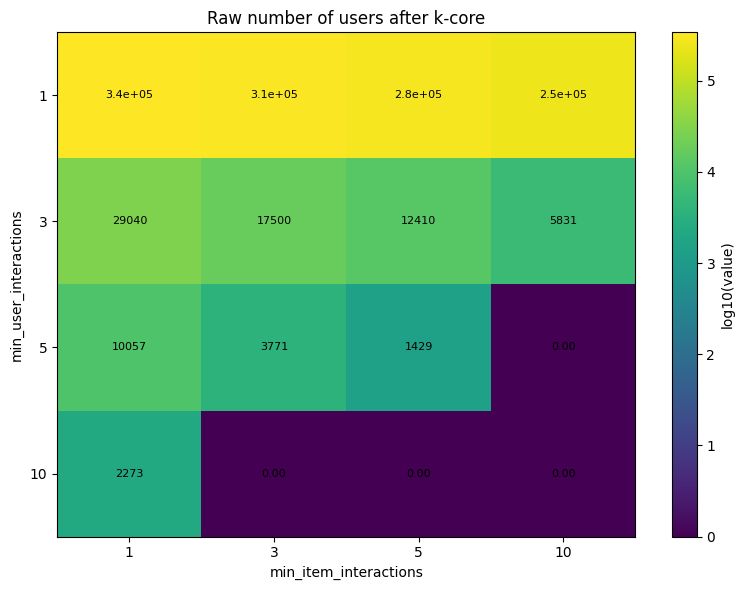

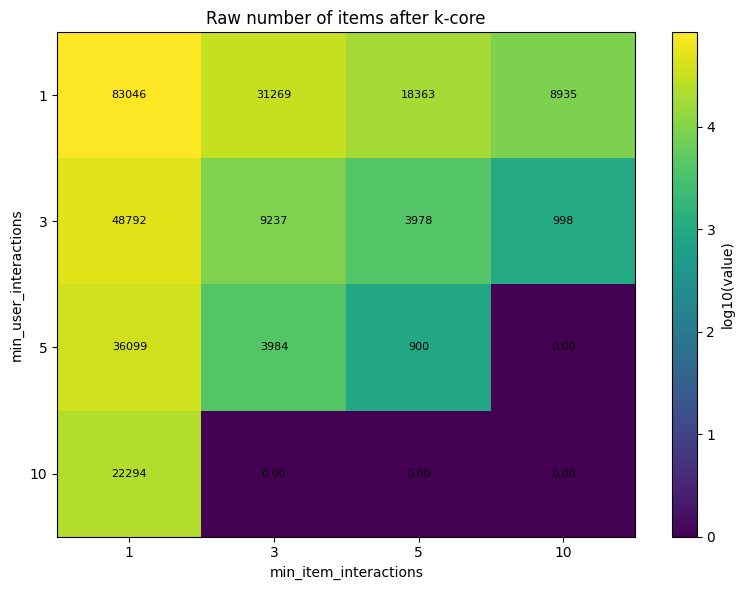

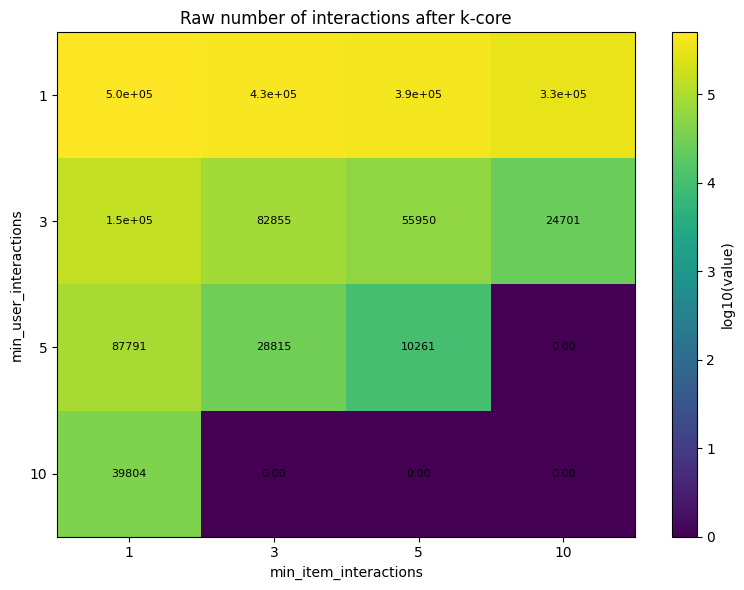

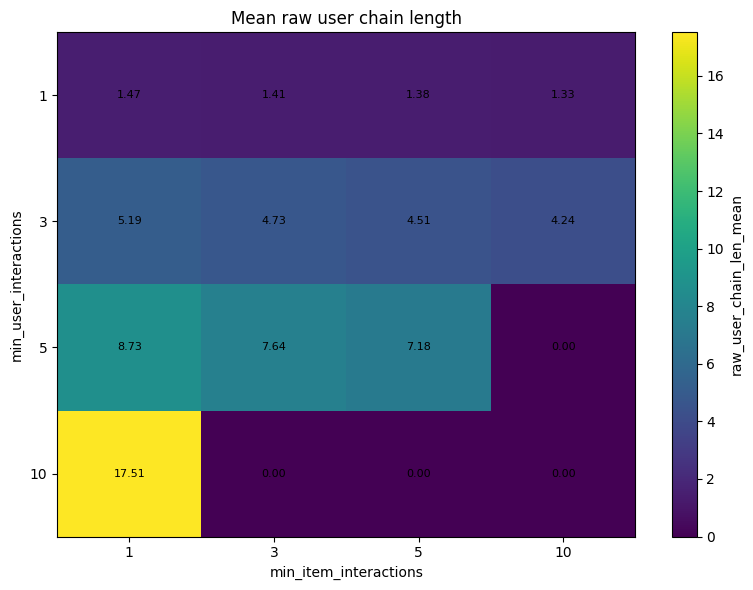

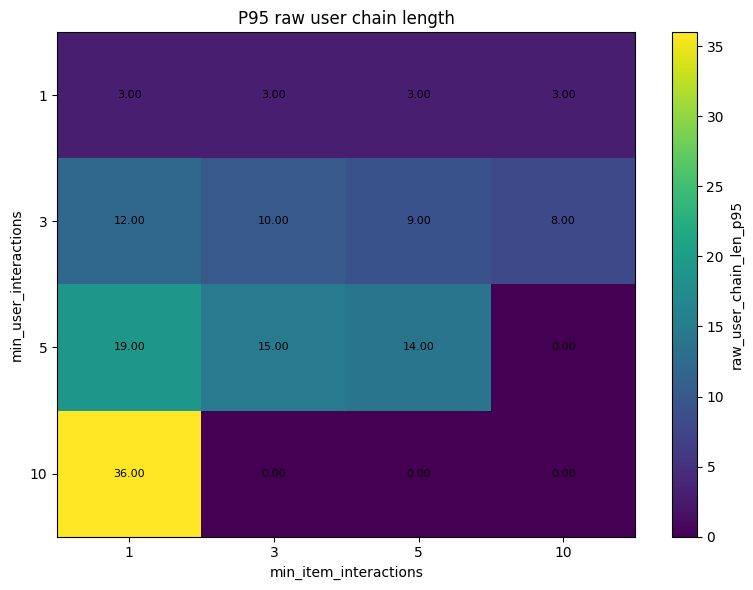

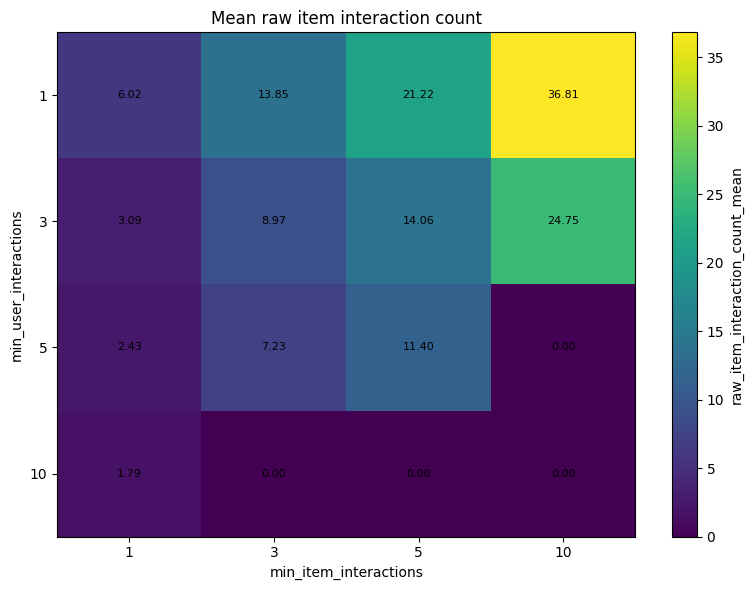

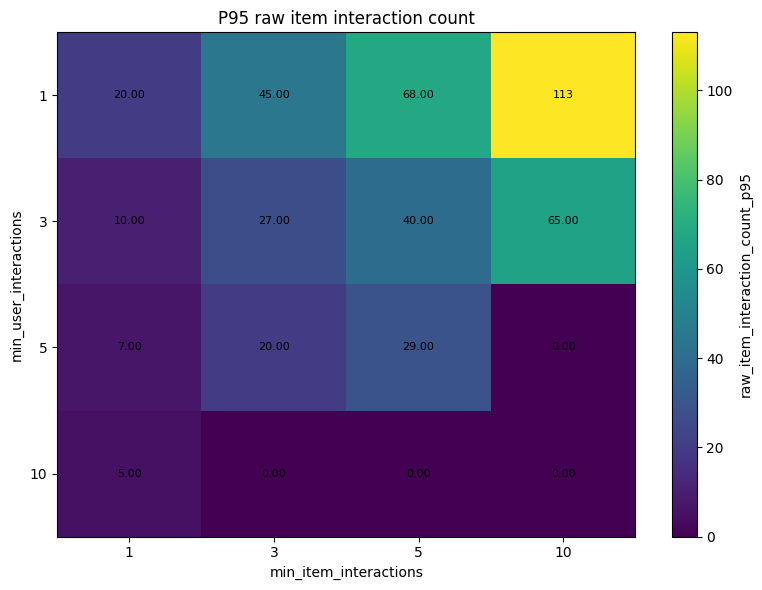

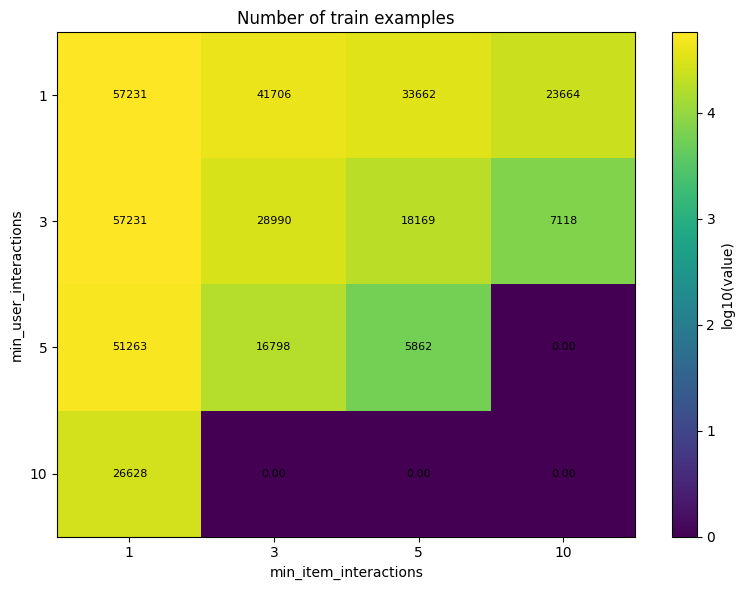

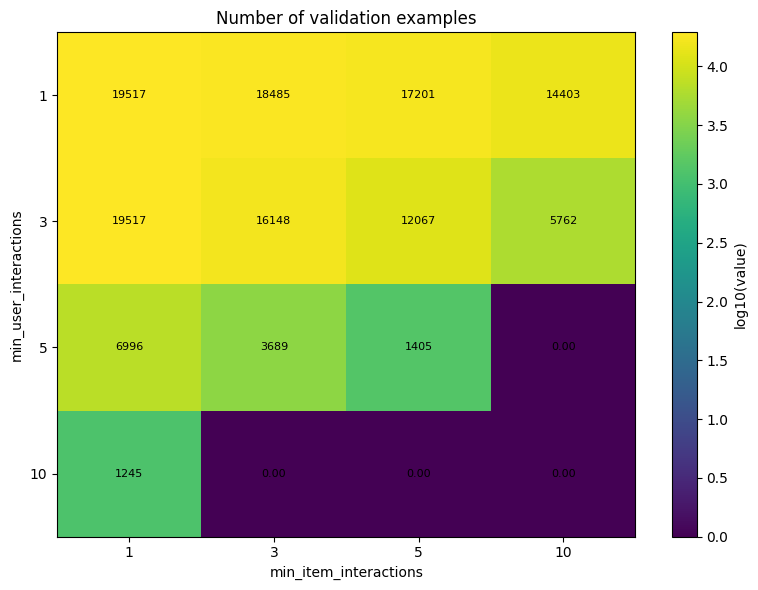

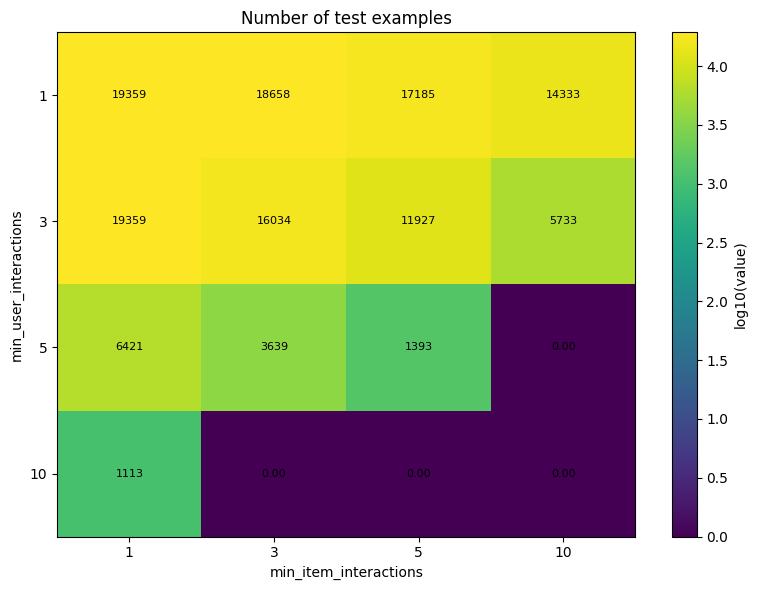

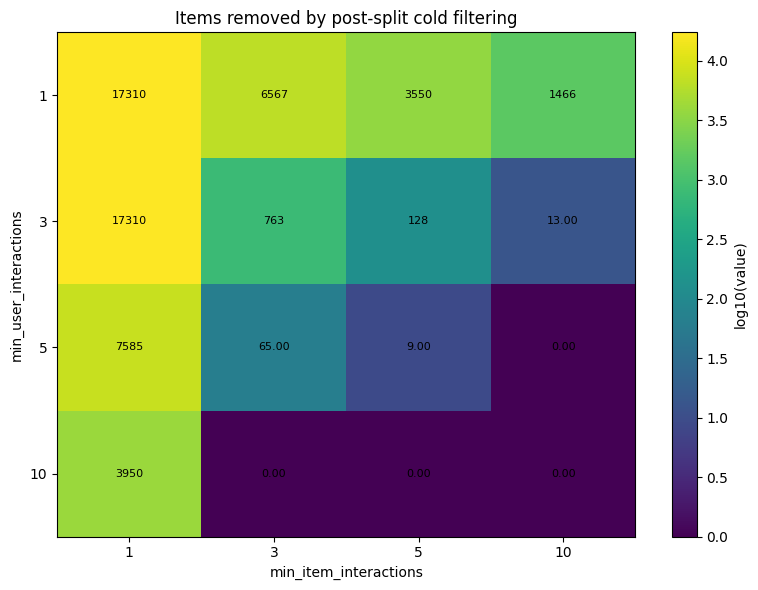

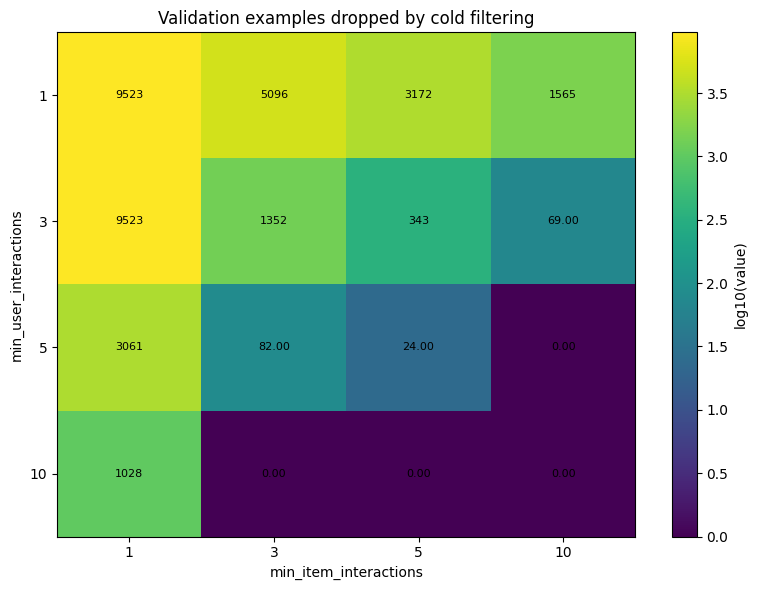

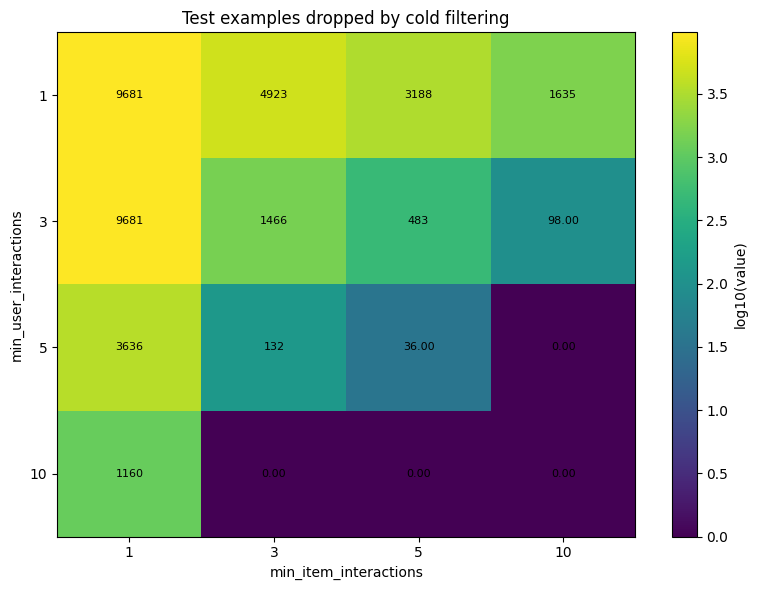

Saved plots to: reports/beauty_filter_stats/plots


In [18]:
save_plots(summary, out_dir)
print(f"Saved plots to: {out_dir / 'plots'}")

## 7. Inspect selected columns

Use this cell to quickly compare the most important statistics across filter settings.

In [19]:
important_cols = [
    "label",
    "raw_num_users_after_kcore",
    "raw_num_items_after_kcore",
    "raw_num_interactions_after_kcore",
    "raw_user_chain_len_mean",
    "raw_user_chain_len_p95",
    "raw_item_interaction_count_mean",
    "raw_item_interaction_count_p95",
    "dm_num_users",
    "dm_num_items",
    "dm_num_interactions",
    "train_num_examples",
    "val_num_examples",
    "test_num_examples",
    "post_filter_num_items_removed",
    "post_filter_dropped_val_examples",
    "post_filter_dropped_test_examples",
]
existing = [c for c in important_cols if c in summary.columns]
display(summary[existing])


,label,raw_num_users_after_kcore,raw_num_items_after_kcore,raw_num_interactions_after_kcore,raw_user_chain_len_mean,raw_user_chain_len_p95,raw_item_interaction_count_mean,raw_item_interaction_count_p95,dm_num_users,dm_num_items,dm_num_interactions,train_num_examples,val_num_examples,test_num_examples,post_filter_num_items_removed,post_filter_dropped_val_examples,post_filter_dropped_test_examples
0,"u≥1, i≥1",339231,83046,500176,1.474441,3.0,6.022879,20.0,29040,31482,500176,57231,19517,19359,17310,9523,9681
1,"u≥1, i≥3",307585,31269,433191,1.408362,3.0,13.853689,45.0,23581,17412,433191,41706,18485,18658,6567,5096,4923
2,"u≥1, i≥5",283023,18363,389631,1.376676,3.0,21.218265,68.0,20373,11883,389631,33662,17201,17185,3550,3172,3188
3,"u≥1, i≥10",246742,8935,328888,1.332923,3.0,36.808954,113.0,15968,6646,328888,23664,14403,14333,1466,1565,1635
4,"u≥3, i≥1",29040,48792,150708,5.189669,12.0,3.088785,10.0,29040,31482,150708,57231,19517,19359,17310,9523,9681
5,"u≥3, i≥3",17500,9237,82855,4.734571,10.0,8.969904,27.0,17500,8474,82855,28990,16148,16034,763,1352,1466
6,"u≥3, i≥5",12410,3978,55950,4.508461,9.0,14.064857,40.0,12410,3850,55950,18169,12067,11927,128,343,483
7,"u≥3, i≥10",5831,998,24701,4.236152,8.0,24.750501,65.0,5831,985,24701,7118,5762,5733,13,69,98
8,"u≥5, i≥1",10057,36099,87791,8.729343,19.0,2.431951,7.0,10057,28514,87791,51263,6996,6421,7585,3061,3636
9,"u≥5, i≥3",3771,3984,28815,7.641209,15.0,7.232681,20.0,3771,3919,28815,16798,3689,3639,65,82,132
